# 01 · Exploratory data analysis

**Dataset:** Extension of Z-Alizadeh Sani (UCI id 411) — 303 patients, 55 clinical features,
four labels: overall CAD (`Cath`) and stenosis of the LAD, LCX and RCA.

This notebook checks label structure, feature types, univariate signal and the leakage guard.
No modelling decisions are fitted here (everything learned happens inside CV folds in `02`).

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from vascora_ml import config, data, models

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
REPORTS = config.REPORTS_DIR
REPORTS.mkdir(exist_ok=True)
TARGETS = data.target_keys()
TARGET_LABELS = {t: data.load_registry()["targets"][t]["label"] for t in TARGETS}
FEATURE_LABELS = {f.key: f.label for f in data.features()}

In [2]:
raw = data.load_raw()
X, Y = data.load_dataset()
print("raw shape:", raw.shape, "| features:", X.shape[1], "| missing values:", int(raw.isna().sum().sum()))
types = pd.Series({f.key: f.type for f in data.features()}).value_counts()
display(types.rename("count").to_frame("features by schema type"))
X.head()

raw shape: (303, 59) | features: 55 | missing values: 0


,features by schema type
number,21
yn,18
binary,11
categorical,3
ordinal,2


,age,weight,height,sex,bmi,dm,htn,current_smoker,ex_smoker,fh,...,hb,k,na,wbc,lymph,neut,plt,ef_tte,region_rwma,vhd
0,53,90,175,Male,29.388,0,1,1,0,0,...,15.6,4.7,141,5700,39,52,261,50,0,N
1,67,70,157,Fmale,28.399,0,1,0,0,0,...,13.9,4.7,156,7700,38,55,165,40,4,N
2,54,54,164,Male,20.077,0,0,1,0,0,...,13.5,4.7,139,7400,38,60,230,40,2,mild
3,66,67,158,Fmale,26.839,0,1,0,0,0,...,12.1,4.4,142,13000,18,72,742,55,0,Severe
4,50,87,153,Fmale,37.165,0,1,0,0,0,...,13.2,4.0,140,9200,55,39,274,50,0,Severe


## Leakage guard

`LAD`, `LCX`, `RCA` and `Cath` are labels. They are excluded from the model inputs for **every**
target (a vessel label would trivially predict CAD and vice-versa). `data.assert_no_leakage`
enforces this at load time and in the unit tests.

In [3]:
data.assert_no_leakage(list(X.columns))
print("excluded from features:", sorted(data.excluded_columns()))
print("label columns present in X:", sorted(set(X.columns) & data.excluded_columns()) or "none")

excluded from features: ['Cath', 'LAD', 'LCX', 'RCA']
label columns present in X: none


## Labels

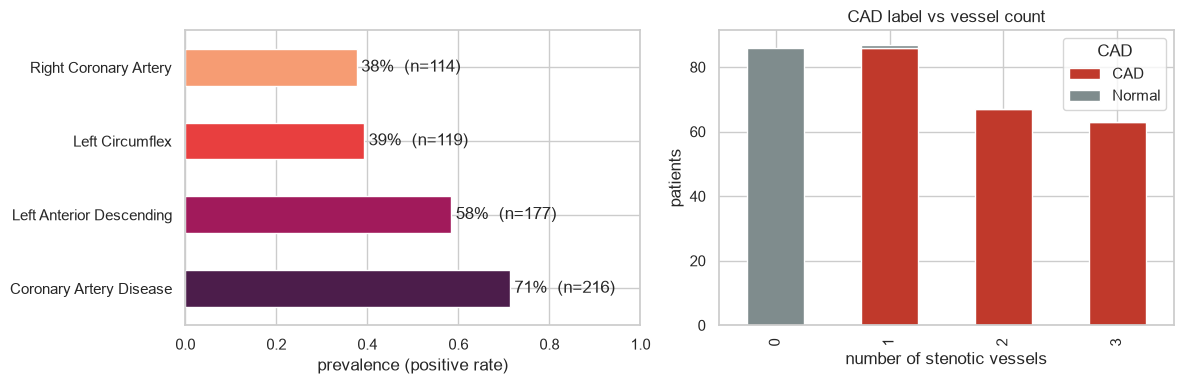

CAD,CAD,Normal
row_0,,
0,0,86
1,86,1
2,67,0
3,63,0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
prev = Y.mean().rename(TARGET_LABELS)
prev.plot.barh(ax=axes[0], color=sns.color_palette("rocket", 4))
axes[0].set_xlim(0, 1); axes[0].set_xlabel("prevalence (positive rate)")
for i, v in enumerate(prev):
    axes[0].text(v + 0.01, i, f"{v:.0%}  (n={int(v * len(Y))})", va="center")

n_vessels = Y[["LAD", "LCX", "RCA"]].sum(axis=1)
ct = pd.crosstab(n_vessels, Y.CAD.map({0: "Normal", 1: "CAD"}))
ct.plot.bar(ax=axes[1], stacked=True, color=["#c0392b", "#7f8c8d"])
axes[1].set_xlabel("number of stenotic vessels"); axes[1].set_ylabel("patients")
axes[1].set_title("CAD label vs vessel count")
plt.tight_layout(); plt.savefig(REPORTS / "eda_labels.png", dpi=150); plt.show()
display(ct)

In [5]:
combo = Y[["LAD", "LCX", "RCA"]].astype(str).agg("".join, axis=1).map(
    lambda s: " + ".join(v for v, b in zip(["LAD", "LCX", "RCA"], s) if b == "1") or "none")
display(combo.value_counts().rename("patients").to_frame())
display(Y.corr().round(2).style.background_gradient(cmap="Reds", vmin=0, vmax=1))

,patients
none,86
LAD + LCX + RCA,63
LAD,57
LAD + LCX,33
LAD + RCA,24
RCA,17
LCX,13
LCX + RCA,10


,CAD,LAD,LCX,RCA
CAD,1.000000,0.740000,0.510000,0.490000
LAD,0.740000,1.000000,0.360000,0.280000
LCX,0.510000,0.360000,1.000000,0.390000
RCA,0.490000,0.280000,0.390000,1.000000


CAD is (almost exactly) "at least one stenotic vessel" — every CAD patient has ≥ 1 stenotic
vessel and only one patient labelled Normal has one. The vessel labels are positively correlated, which motivates testing a
**classifier chain** (CAD → LAD → LCX → RCA) against independent per-target models in `02`.

## Univariate signal

Single-feature ROC-AUC (|AUC − 0.5| measures ranking signal regardless of direction) for every
feature and target. Encoding: `data.encode_base` (Y/N → 1/0, categorical → option index).

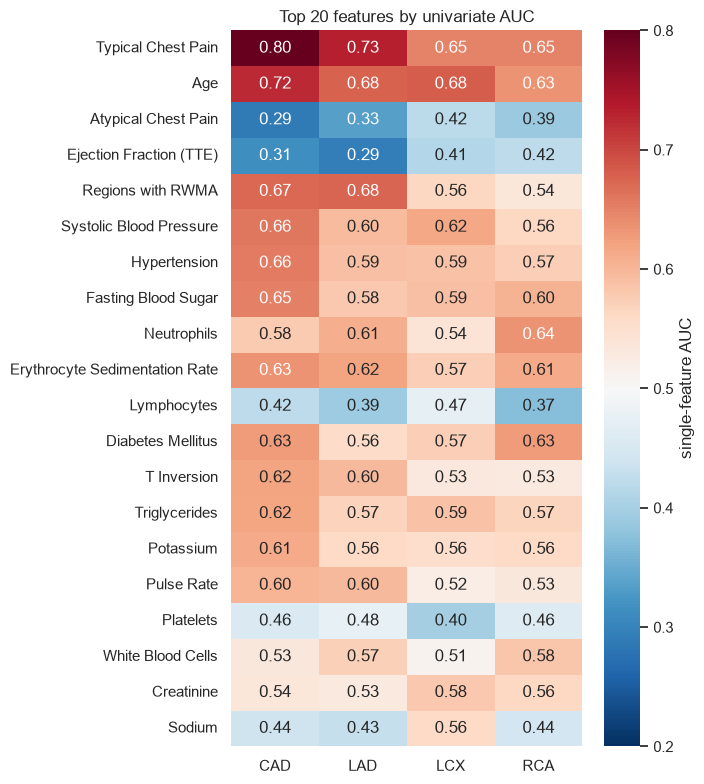

In [6]:
from sklearn.metrics import roc_auc_score

Xb = data.encode_base(X)
uni = pd.DataFrame({t: {k: roc_auc_score(Y[t], Xb[k]) if Xb[k].nunique() > 1 else 0.5
                        for k in Xb.columns} for t in TARGETS})
strength = (uni - 0.5).abs()
top = strength.max(axis=1).sort_values(ascending=False).head(20).index
fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(uni.loc[top].rename(index=FEATURE_LABELS), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0.5, vmin=0.2, vmax=0.8, ax=ax, cbar_kws={"label": "single-feature AUC"})
ax.set_title("Top 20 features by univariate AUC")
plt.tight_layout(); plt.savefig(REPORTS / "eda_univariate_auc.png", dpi=150); plt.show()

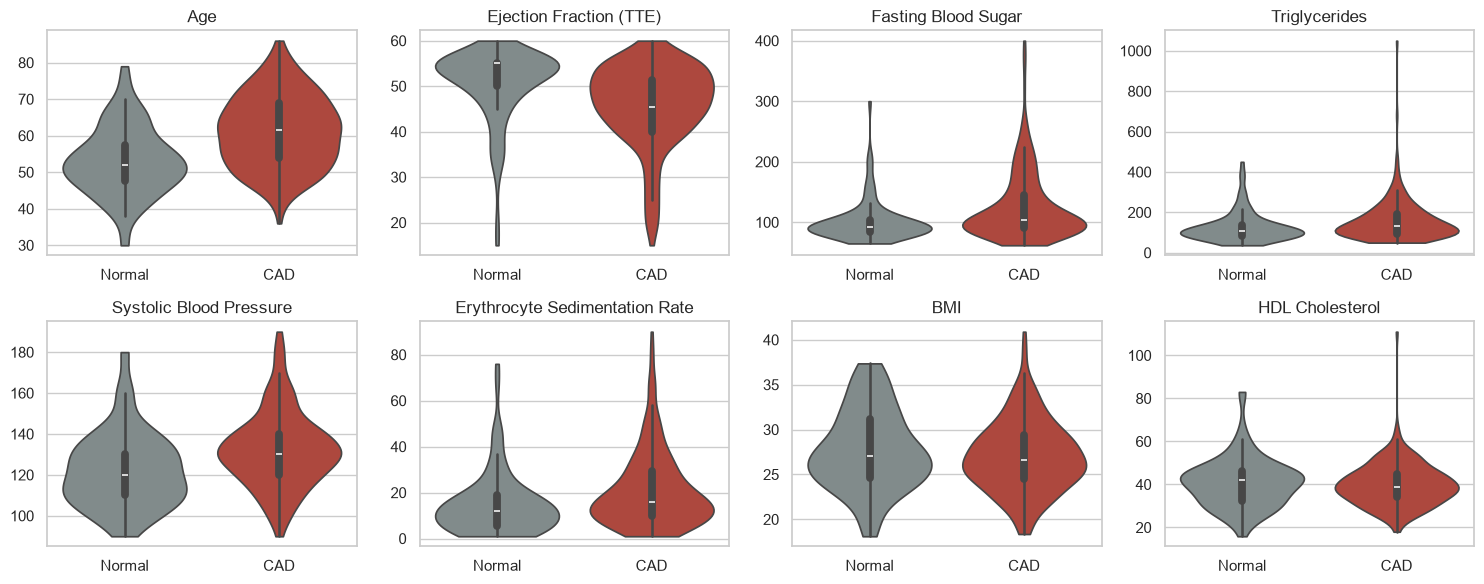

In [7]:
key_numeric = ["age", "ef_tte", "fbs", "tg", "bp", "esr", "bmi", "hdl"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
plot_df = X.assign(CAD=Y.CAD.map({0: "Normal", 1: "CAD"}))
for ax, k in zip(axes.ravel(), key_numeric):
    sns.violinplot(data=plot_df, x="CAD", y=k, ax=ax, palette=["#7f8c8d", "#c0392b"], cut=0,
                   order=["Normal", "CAD"])
    ax.set_title(FEATURE_LABELS[k]); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(REPORTS / "eda_numeric_by_cad.png", dpi=150); plt.show()

In [8]:
binary = [f.key for f in data.features() if f.type in ("binary", "yn")]
rates = pd.DataFrame({
    "prevalence": Xb[binary].mean(),
    "CAD rate if present": [Y.CAD[Xb[k] == 1].mean() for k in binary],
    "CAD rate if absent": [Y.CAD[Xb[k] == 0].mean() for k in binary],
}).rename(index=FEATURE_LABELS)
rates["lift"] = rates["CAD rate if present"] - rates["CAD rate if absent"]
rates.sort_values("lift", ascending=False)

,prevalence,CAD rate if present,CAD rate if absent,lift
Typical Chest Pain,0.541,0.939,0.446,0.493
Q Wave,0.053,1.000,0.697,0.303
ST Elevation,0.046,1.000,0.699,0.301
Poor R-Wave Progression,0.030,1.000,0.704,0.296
Chronic Renal Failure,0.020,1.000,0.707,0.293
Weak Peripheral Pulse,0.017,1.000,0.708,0.292
Low-Threshold Angina,0.007,1.000,0.711,0.289
Congestive Heart Failure,0.003,1.000,0.712,0.288
Hypertension,0.591,0.821,0.556,0.265
Diabetes Mellitus,0.297,0.889,0.638,0.250


**Notes for modelling**

* No missing values; `Exertional CP` is constant (all "N") and is dropped inside the pipeline.
* Strongest univariate signals: typical chest pain, age, diabetes/FBS, hypertension, regional
  wall-motion abnormality, EF and chest-pain subtype (atypical / non-anginal are protective).
* n = 303 is small, so validation rigor (nested CV + untouched hold-out) matters more than model
  size; all preprocessing that learns from data lives inside the CV pipelines.